# Part 4 — Pretrained visual representations: CNN, DINOv2 and CLIP

All stages of Part 4 run on the **frozen features cached by
`src.extract_deep`** (`data/encodings/<feature>/`). Run this notebook from
`code/`. If a feature folder is missing, extract it first:

In [9]:
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch

from src import evaluate as ev
from src.evaluate import CLASSES

OUT = ev.ROOT / "results" / "part4"
FIG = OUT / "figs"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)


def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")


device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Python {platform.python_version()} | torch {torch.__version__} | "
      f"scikit-learn {sklearn.__version__} | numpy {np.__version__}")
print("Device:", torch.cuda.get_device_name(0) if device == "cuda" else platform.processor())

costs = ev.extraction_costs()       # from results/deep_extraction.csv
costs[["dim", "device", "ms_per_img_total", "ms_per_img_forward", "model_load_s"]]

Python 3.11.17 | torch 2.14.0+cu130 | scikit-learn 1.9.1 | numpy 2.4.6
Device: NVIDIA GeForce RTX 5060 Ti


,dim,device,ms_per_img_total,ms_per_img_forward,model_load_s
feature,,,,,
resnet18_layer2,128,NVIDIA GeForce RTX 5060 Ti,3.923,0.427,0.19
resnet18_layer3,256,NVIDIA GeForce RTX 5060 Ti,3.923,0.427,0.19
resnet18_layer4,512,NVIDIA GeForce RTX 5060 Ti,3.923,0.427,0.19
vit_b_32,768,NVIDIA GeForce RTX 5060 Ti,4.108,0.873,0.58
dinov2_vits14,384,NVIDIA GeForce RTX 5060 Ti,4.538,1.524,1.16
dinov2_vits14_patchmean,384,NVIDIA GeForce RTX 5060 Ti,4.538,1.524,1.16
clip_vit_b_32,512,NVIDIA GeForce RTX 5060 Ti,3.826,0.367,1.85


## Stage A — Frozen CNN features (ResNet-18) and supervised ViT

ResNet-18 (ImageNet weights, torchvision): global average pooling of the last
block of each of the final 3 stages: `layer2.1` (128-D), `layer3.1` (256-D)
and `layer4.1` (512-D). The supervised ViT-B/32 CLS token (768-D) covers the
"CNN/ViT + SVM" row of the comparison table.

In [10]:
results = {}
for f in ["resnet18_layer2", "resnet18_layer3", "resnet18_layer4", "vit_b_32"]:
    results[f] = ev.evaluate_feature(f)

resnet18_layer2            dim= 128  aerop=0.780  car=0.807  horse=0.702  motor=0.796  perso=0.868  mAP=0.790
resnet18_layer3            dim= 256  aerop=0.901  car=0.898  horse=0.851  motor=0.903  perso=0.960  mAP=0.903
resnet18_layer4            dim= 512  aerop=0.978  car=0.966  horse=0.958  motor=0.982  perso=0.972  mAP=0.971
vit_b_32                   dim= 768  aerop=0.995  car=0.971  horse=0.966  motor=0.982  perso=0.958  mAP=0.974


In [11]:
apA = ev.ap_table(results)
apA["dim"] = [results[f]["dim"] for f in apA.index]
apA.to_csv(OUT / "stageA_test_ap.csv")
apA

class,aeroplane,car,horse,motorbike,person,mAP,dim
resnet18_layer2,0.780,0.807,0.702,0.796,0.868,0.790,128
resnet18_layer3,0.901,0.898,0.851,0.903,0.960,0.903,256
resnet18_layer4,0.978,0.966,0.958,0.982,0.972,0.971,512
vit_b_32,0.995,0.971,0.966,0.982,0.958,0.974,768


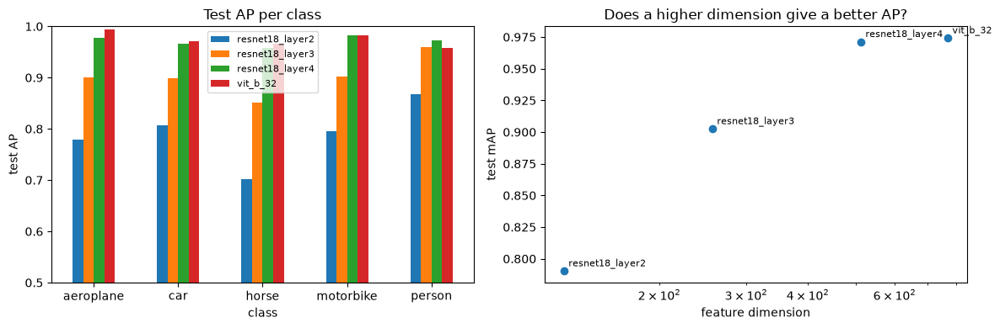

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# test AP per class
apA[CLASSES].T.plot.bar(ax=axes[0], rot=0)
axes[0].set_ylim(0.5, 1.0)
axes[0].set_ylabel("test AP")
axes[0].set_title("Test AP per class")
axes[0].legend(fontsize=8)

# mAP vs feature dimension
axes[1].scatter(apA["dim"], apA["mAP"])
for f, row in apA.iterrows():
    axes[1].annotate(f, (row["dim"], row["mAP"]), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
axes[1].set_xscale("log")
axes[1].set_xlabel("feature dimension")
axes[1].set_ylabel("test mAP")
axes[1].set_title("Does a higher dimension give a better AP?")
fig.tight_layout()
savefig(fig, "stageA_ap")

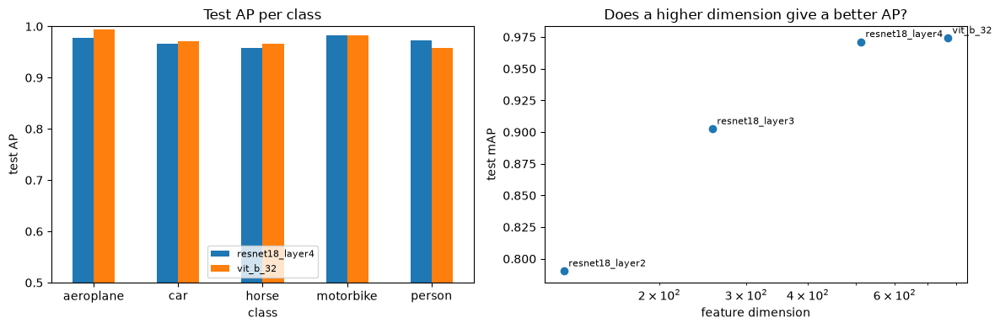

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# test AP per class of the best performing features (resnet18 layer 4 and vit_b_32)
apA.loc[["resnet18_layer4", "vit_b_32"], CLASSES].T.plot.bar(ax=axes[0], rot=0)
axes[0].set_ylim(0.5, 1.0)
axes[0].set_ylabel("test AP")
axes[0].set_title("Test AP per class")
axes[0].legend(fontsize=8)

# mAP vs feature dimension
axes[1].scatter(apA["dim"], apA["mAP"])
for f, row in apA.iterrows():
    axes[1].annotate(f, (row["dim"], row["mAP"]), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
axes[1].set_xscale("log")
axes[1].set_xlabel("feature dimension")
axes[1].set_ylabel("test mAP")
axes[1].set_title("Does a higher dimension give a better AP?")
fig.tight_layout() 
savefig(fig, "stageA_ap_best")

## Stage B — DINOv2 feature extraction

DINOv2 ViT-S/14 (Torch Hub, backbone frozen): Resize 256 → CenterCrop 224 →
ImageNet normalisation (224 = 16 × 14 patches). Global representation = the
normalised CLS token (384-D). Optional extension: the mean of the 256 patch
tokens (`dinov2_vits14_patchmean`). CLIP image embeddings are also evaluated
here, for the comparison in Stage E.

In [14]:
for f in ["dinov2_vits14", "dinov2_vits14_patchmean", "clip_vit_b_32"]:
    results[f] = ev.evaluate_feature(f)

dinov2_vits14              dim= 384  aerop=1.000  car=0.977  horse=0.998  motor=0.983  perso=0.983  mAP=0.988
dinov2_vits14_patchmean    dim= 384  aerop=1.000  car=0.979  horse=0.992  motor=0.988  perso=0.990  mAP=0.990
clip_vit_b_32              dim= 512  aerop=0.999  car=0.986  horse=0.989  motor=0.992  perso=0.992  mAP=0.992


In [15]:
DEEP = ["resnet18_layer2", "resnet18_layer3", "resnet18_layer4", "vit_b_32",
        "dinov2_vits14", "dinov2_vits14_patchmean", "clip_vit_b_32"]
multi = {f: ev.evaluate_multiclass(f) for f in DEEP}

resnet18_layer2            C=100.0  aerop=0.616  car=0.651  horse=0.211  motor=0.278  perso=0.788  mAP(vs all)=0.509
resnet18_layer3            C=100.0  aerop=0.837  car=0.731  horse=0.324  motor=0.512  perso=0.909  mAP(vs all)=0.663
resnet18_layer4            C=10.0   aerop=0.951  car=0.855  horse=0.781  motor=0.859  perso=0.912  mAP(vs all)=0.872
vit_b_32                   C=0.1    aerop=0.985  car=0.914  horse=0.877  motor=0.950  perso=0.861  mAP(vs all)=0.918
dinov2_vits14              C=1.0    aerop=0.992  car=0.913  horse=0.987  motor=0.923  perso=0.929  mAP(vs all)=0.949
dinov2_vits14_patchmean    C=1.0    aerop=0.988  car=0.936  horse=0.976  motor=0.898  perso=0.954  mAP(vs all)=0.950
clip_vit_b_32              C=10.0   aerop=0.986  car=0.923  horse=0.976  motor=0.932  perso=0.945  mAP(vs all)=0.952


Per-class metrics, DINOv2 CLS (test):


,precision,recall,f1-score,support
aeroplane,0.974,1.000,0.987,112.000
car,0.931,0.890,0.910,228.000
horse,1.000,0.774,0.873,31.000
motorbike,0.968,0.811,0.882,37.000
person,0.938,0.883,0.910,684.000
background,0.914,0.965,0.939,1077.000
accuracy,0.928,0.928,0.928,0.928
macro avg,0.954,0.887,0.917,2169.000
weighted avg,0.928,0.928,0.927,2169.000


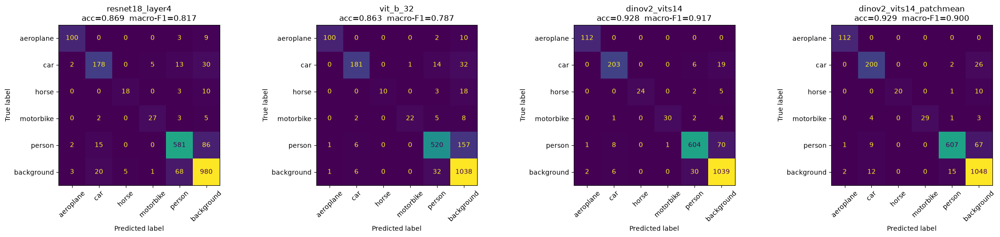

In [16]:
shown = ["resnet18_layer4", "vit_b_32", "dinov2_vits14", "dinov2_vits14_patchmean"]
fig, axes = plt.subplots(1, len(shown), figsize=(5.5 * len(shown), 5))
reports = {}
for ax, f in zip(axes, shown):
    _, reports[f] = ev.confusion(multi[f]["scores"], multi[f]["test"], f, ax=ax)
fig.tight_layout()
savefig(fig, "stageB_confusion")

print("Per-class metrics, DINOv2 CLS (test):")
reports["dinov2_vits14"]

In [17]:
ap_all = pd.DataFrame({f: multi[f]["ap_vs_all"] for f in DEEP}).T
ap_all["mAP"] = ap_all[CLASSES].mean(1)
ap_all["C"] = [multi[f]["C"] for f in DEEP]
ap_all.to_csv(OUT / "stageB_test_ap_vs_all.csv")
ap_all

C:\Users\Utilizador\AppData\Local\Temp\ipykernel_2664\3130996223.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  ap_all["mAP"] = ap_all[CLASSES].mean(1)


,aeroplane,car,horse,motorbike,person,mAP,C
resnet18_layer2,0.616,0.651,0.211,0.278,0.788,0.509,100.0
resnet18_layer3,0.837,0.731,0.324,0.512,0.909,0.663,100.0
resnet18_layer4,0.951,0.855,0.781,0.859,0.912,0.872,10.0
vit_b_32,0.985,0.914,0.877,0.950,0.861,0.918,0.1
dinov2_vits14,0.992,0.913,0.987,0.923,0.929,0.949,1.0
dinov2_vits14_patchmean,0.988,0.936,0.976,0.898,0.954,0.950,1.0
clip_vit_b_32,0.986,0.923,0.976,0.932,0.945,0.952,10.0


### Cost of each representation

* extraction = decode + preprocessing + forward pass per image (batch 64,
  from `deep_extraction.csv`); model loading is listed separately;
* SVM training = the 5 final binary SVMs;
* SVM inference = scoring the 5 classes of one already-extracted feature.

In [18]:
cost_table = pd.DataFrame({
    "dim": [results[f]["dim"] for f in DEEP],
    "test mAP vs bg": [results[f]["per_class"].test_ap.mean() for f in DEEP],
    "test mAP vs all": ap_all.loc[DEEP, "mAP"].values,
    "extract ms/img": costs.loc[DEEP, "ms_per_img_total"].values,
    "forward ms/img": costs.loc[DEEP, "ms_per_img_forward"].values,
    "model load s": costs.loc[DEEP, "model_load_s"].values,
    "SVM train s": [results[f]["per_class"].train_s.sum() for f in DEEP],
    "SVM infer µs/img": [results[f]["infer_us"] for f in DEEP],
    "storage B/img": [results[f]["dim"] * 4 for f in DEEP],   # float32
}, index=DEEP)
cost_table.to_csv(OUT / "stageB_costs.csv")
cost_table

,dim,test mAP vs bg,test mAP vs all,extract ms/img,forward ms/img,model load s,SVM train s,SVM infer µs/img,storage B/img
resnet18_layer2,128,0.790,0.509,3.923,0.427,0.19,0.572,0.397,512
resnet18_layer3,256,0.903,0.663,3.923,0.427,0.19,0.190,0.536,1024
resnet18_layer4,512,0.971,0.872,3.923,0.427,0.19,0.093,0.828,2048
vit_b_32,768,0.974,0.918,4.108,0.873,0.58,0.109,1.207,3072
dinov2_vits14,384,0.988,0.949,4.538,1.524,1.16,0.076,0.635,1536
dinov2_vits14_patchmean,384,0.990,0.950,4.538,1.524,1.16,0.051,0.793,1536
clip_vit_b_32,512,0.992,0.952,3.826,0.367,1.85,0.086,0.822,2048


## Stage C — Few-shot learning and augmentation

Representation: DINOv2 CLS (`dinov2_vits14`). For each class, k ∈ {1, 5, 10,
20, all} positives are sampled from train with 5 seeds (0–4); **the negatives
are always all 815 background images of train**. C is fixed at 1, so the
val AP is not biased by tuning C for each k (C is studied in Stage D).

Augmentation: the features of the horizontally mirrored training images
(`dinov2_vits14_flip`) are added to the training set. Validation images are
never augmented.

In [19]:
fs = ev.few_shot("dinov2_vits14")
fs.to_csv(OUT / "stageC_few_shot_dinov2.csv", index=False)
fs.groupby(["k", "flip"], sort=False).val_ap.agg(["mean", "std"]).unstack()

mean           std       
flip  False  True   False  True 
k                               
1     0.808  0.800  0.171  0.177
5     0.946  0.946  0.057  0.059
10    0.967  0.966  0.041  0.042
20    0.973  0.974  0.035  0.034
all   0.992  0.991  0.015  0.015

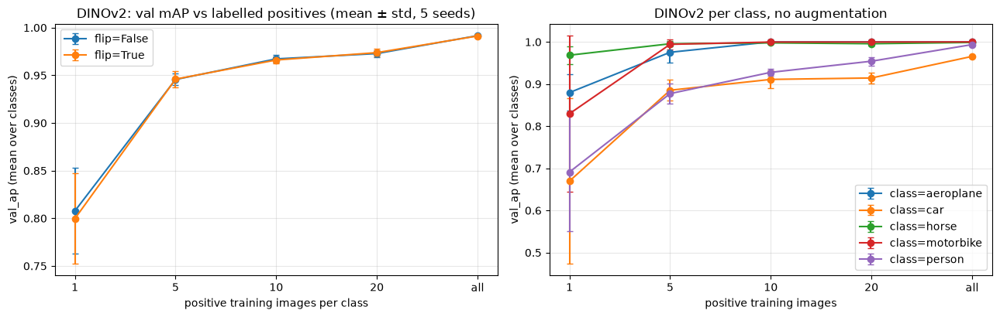

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ev.plot_curve(fs, "k", hue="flip", ax=axes[0],
              xlabel="positive training images per class",
              title="DINOv2: val mAP vs labelled positives (mean ± std, 5 seeds)")
ev.plot_curve(fs[~fs.flip], "k", hue="class", ax=axes[1],
              xlabel="positive training images",
              title="DINOv2 per class, no augmentation")
fig.tight_layout()
savefig(fig, "stageC_few_shot_dinov2")

k,1,5,10,20,all
feature,,,,,
dinov2_vits14,0.808,0.946,0.967,0.973,0.992
resnet18_layer4,0.751,0.927,0.956,0.963,0.985
vit_b_32,0.817,0.921,0.936,0.949,0.983
clip_vit_b_32,0.895,0.972,0.987,0.987,0.994
bovw_K256_C0_hellinger,0.315,0.395,0.514,0.563,0.758
vlad_K32_C80,0.353,0.474,0.537,0.610,0.770
fv_K32_C80,0.318,0.416,0.499,0.544,0.723


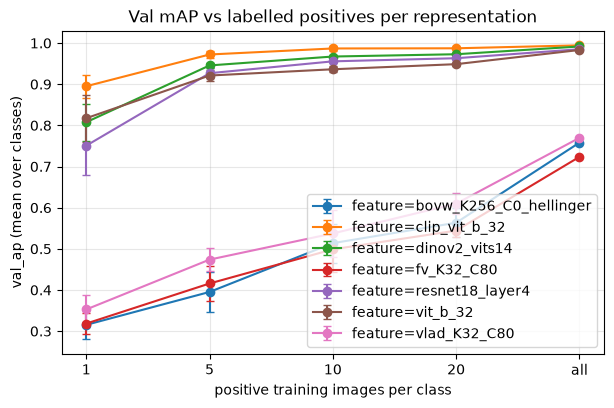

In [21]:
others = ["resnet18_layer4", "vit_b_32", "clip_vit_b_32"]
others += [f for f in HANDCRAFTED if ev.has_feature(f)]
fs_all = [fs[~fs.flip].assign(feature="dinov2_vits14")]
for f in others:
    fs_all.append(ev.few_shot(f, flip=(False,)).assign(feature=f))
fs_all = pd.concat(fs_all, ignore_index=True)
fs_all.to_csv(OUT / "stageC_few_shot_features.csv", index=False)

NAMES = {"dinov2_vits14": "DINOv2 CLS", "clip_vit_b_32": "CLIP ViT-B/32",
         "resnet18_layer4": "ResNet-18 layer4", "vit_b_32": "ViT-B/32",
         "bovw_K256_C0_hellinger": "BoVW K=256 Hellinger",
         "vlad_K32_C80": "VLAD K=32", "fv_K32_C80": "FV K=32"}
fig, ax = plt.subplots(figsize=(7, 4.2))
ev.plot_curve(fs_all.assign(feature=fs_all.feature.map(NAMES)), "k", hue="feature", ax=ax,
              xlabel="positive training images per class",
              title="Val mAP vs labelled positives per representation")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [l.split("=", 1)[1] for l in labels], fontsize=8,
          loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.set_ylabel("val mAP")
savefig(fig, "stageC_few_shot_features")
fs_all.groupby(["feature", "k"], sort=False).val_ap.mean().unstack()

In [22]:
tta = ev.tta_check("dinov2_vits14", results["dinov2_vits14"]["W"],
                   results["dinov2_vits14"]["b"])
tta.to_csv(OUT / "stageC_tta_check.csv")
tta

,AP no TTA,AP mean of scores,AP mean of features,AP mean of features + L2,max |score difference|
class,,,,,
aeroplane,1.000,1.000,1.000,1.000,2.674e-08
car,0.966,0.965,0.965,0.965,5.068e-08
horse,1.000,1.000,1.000,1.000,1.693e-08
motorbike,1.000,1.000,1.000,1.000,3.172e-08
person,0.994,0.994,0.994,0.994,8.388e-08


## Stage D — Hyperparameter selection (C)

Train and val AP for C ∈ {0.01, 0.1, 1, 10, 100, 1000}: with all training
positives (the sweep used for model selection in Stages A/B), and with only 5
positives per class (5 seeds). The C chosen on val is then evaluated once on
test (the test AP of Stages A/B).

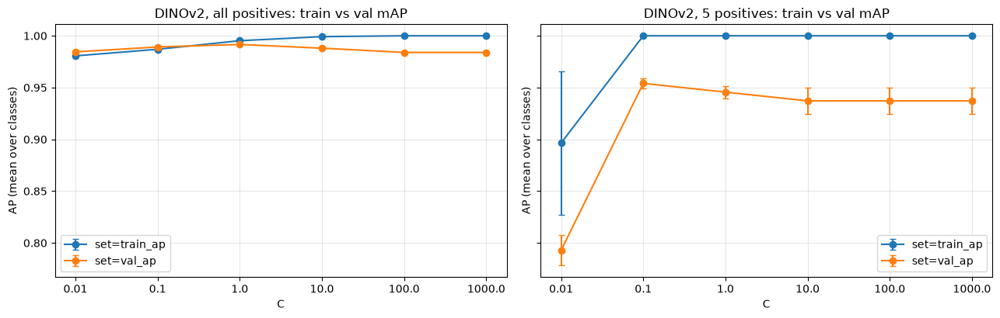

In [23]:
sweep_all = results["dinov2_vits14"]["sweep"].assign(seed=0)
sweep_k5 = ev.few_shot_c_sweep("dinov2_vits14", k=5)
sweep_all.to_csv(OUT / "stageD_C_sweep_all_dinov2.csv", index=False)
sweep_k5.to_csv(OUT / "stageD_C_sweep_k5_dinov2.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, df, name in [(axes[0], sweep_all, "all positives"), (axes[1], sweep_k5, "5 positives")]:
    # one row per (class, C, seed, set) so train and val become two lines
    long = df.melt(id_vars=["class", "C", "seed"], value_vars=["train_ap", "val_ap"],
                   var_name="set", value_name="AP")
    ev.plot_curve(long, "C", y="AP", hue="set", ax=ax,
                  title=f"DINOv2, {name}: train vs val mAP")
fig.tight_layout()
savefig(fig, "stageD_C_sweep")

In [24]:
print("C chosen on val for each feature and class:")
pd.DataFrame({f: r["per_class"].set_index("class")["C"] for f, r in results.items()}).T

C chosen on val for each feature and class:


class,aeroplane,car,horse,motorbike,person
resnet18_layer2,10.0,100.0,1.0,100.0,100.0
resnet18_layer3,10.0,10.0,1.0,10.0,10.0
resnet18_layer4,0.1,1.0,1.0,1.0,1.0
vit_b_32,1.0,1.0,1.0,1.0,1.0
dinov2_vits14,1.0,1.0,0.1,1.0,1.0
dinov2_vits14_patchmean,1.0,1.0,1.0,1.0,1.0
clip_vit_b_32,1.0,1.0,1.0,1.0,1.0


## Stage E — CLIP zero-shot classification

CLIP ViT-B/32 (OpenAI `clip` package, official preprocessing). The image
embeddings are the cached `clip_vit_b_32` features; prompts are encoded with
the CLIP text encoder; score = cosine similarity.

* **Classification:** predicted class = most similar class prompt.
* **Retrieval:** for each class, rank the images (class vs background, as for
  the SVMs) by similarity to the class prompt → AP / mAP.
* **Prompt selection:** single templates and a 7-template ensemble, with and
  without synonyms (e.g. *airplane, motorcycle*), chosen on **val mAP only**.
  The test columns are shown only to discuss prompt sensitivity.

In [25]:
t0 = time.perf_counter()
clip_model = ev.load_clip(device)
print(f"CLIP model load: {time.perf_counter() - t0:.2f} s")

clip_val = ev.load_split("clip_vit_b_32", "val")
clip_test = ev.load_split("clip_vit_b_32", "test")
prompts = ev.prompt_selection(clip_model, clip_val, clip_test)
prompts.to_csv(OUT / "stageE_prompt_selection.csv", index=False)
prompts.sort_values("val_mAP", ascending=False)

c:\Users\Utilizador\anaconda3\envs\cvc-a2\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


CLIP model load: 2.08 s


,templates,synonyms,val_mAP,val_acc,test_mAP,test_acc
0,{},False,0.865,0.727,0.840,0.714
1,{},True,0.861,0.814,0.847,0.816
5,a picture of a {}.,True,0.848,0.866,0.828,0.878
9,ensemble (7 templates),True,0.846,0.874,0.834,0.887
8,ensemble (7 templates),False,0.844,0.853,0.830,0.857
4,a picture of a {}.,False,0.844,0.805,0.825,0.828
2,a photo of a {}.,False,0.840,0.844,0.826,0.857
3,a photo of a {}.,True,0.840,0.879,0.827,0.895
7,a blurry photo of a {}.,True,0.827,0.879,0.810,0.913
6,a blurry photo of a {}.,False,0.818,0.870,0.801,0.896


In [26]:
best = prompts.loc[prompts.val_mAP.idxmax()]
print(f"Chosen on val: templates='{best.templates}', synonyms={best.synonyms}")
templates = ev.TEMPLATES[best.templates]

t0 = time.perf_counter()
text_emb = ev.class_text_embeddings(clip_model, templates, best.synonyms)
print(f"Text encoding of the chosen prompts: {1000 * (time.perf_counter() - t0):.1f} ms (once)")

S_test, zs_ap, _ = ev.zero_shot_eval(clip_test, text_emb)
_, plain_ap, _ = ev.zero_shot_eval(
    clip_test, ev.class_text_embeddings(clip_model, ["a photo of a {}."]))

zs = pd.DataFrame({
    "zero-shot, 'a photo of a {}.'": plain_ap,
    "zero-shot, chosen prompts": zs_ap,
    "linear SVM on CLIP embeddings": results["clip_vit_b_32"]["per_class"]
                                     .set_index("class")["test_ap"],
}).T
zs["mAP"] = zs[CLASSES].mean(1)
zs.to_csv(OUT / "stageE_zero_shot_vs_svm.csv")
zs

Chosen on val: templates='{}', synonyms=False
Text encoding of the chosen prompts: 34.5 ms (once)


C:\Users\Utilizador\AppData\Local\Temp\ipykernel_2664\1159277647.py:19: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  zs["mAP"] = zs[CLASSES].mean(1)


,aeroplane,car,horse,motorbike,person,mAP
"zero-shot, 'a photo of a {}.'",0.983,0.865,0.811,0.889,0.583,0.826
"zero-shot, chosen prompts",0.949,0.865,0.899,0.944,0.545,0.840
linear SVM on CLIP embeddings,0.999,0.986,0.989,0.992,0.992,0.992


,precision,recall,f1-score,support
aeroplane,0.463,1.000,0.633,112.000
car,0.822,0.930,0.872,228.000
horse,0.431,1.000,0.602,31.000
motorbike,0.283,0.973,0.439,37.000
person,0.990,0.569,0.722,684.000
accuracy,0.714,0.714,0.714,0.714
macro avg,0.598,0.894,0.654,1092.000
weighted avg,0.861,0.714,0.731,1092.000


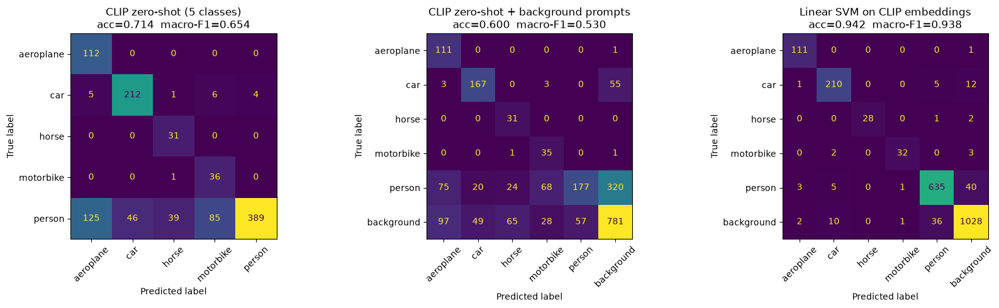

In [27]:
# Zero-shot with 5 class prompts, zero-shot with extra background prompts
# (6 classes), and the multi-class SVM on the same CLIP image embeddings.
emb_bg = ev.class_text_embeddings(clip_model, templates, best.synonyms, background=True)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
_, rep_zs = ev.confusion(S_test, clip_test, "CLIP zero-shot (5 classes)", ax=axes[0])
ev.confusion(clip_test.X @ emb_bg.T, clip_test, "CLIP zero-shot + background prompts", ax=axes[1])
ev.confusion(multi["clip_vit_b_32"]["scores"], clip_test, "Linear SVM on CLIP embeddings", ax=axes[2])
fig.tight_layout()
savefig(fig, "stageE_confusion")
rep_zs

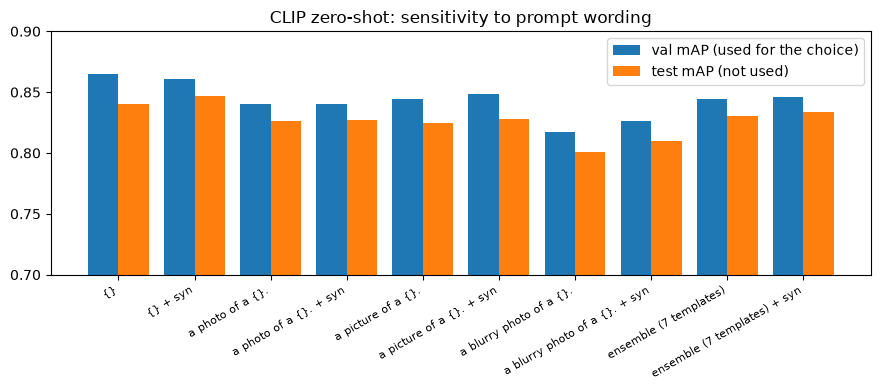

In [28]:
fig, ax = plt.subplots(figsize=(9, 4))
labels = prompts.templates + np.where(prompts.synonyms, " + syn", "")
x = np.arange(len(prompts))
ax.bar(x - .2, prompts.val_mAP, .4, label="val mAP (used for the choice)")
ax.bar(x + .2, prompts.test_mAP, .4, label="test mAP (not used)")
ax.set_xticks(x, labels, rotation=30, ha="right", fontsize=8)
ax.set_ylim(0.7, 0.9)
ax.set_title("CLIP zero-shot: sensitivity to prompt wording")
ax.legend()
fig.tight_layout()
savefig(fig, "stageE_prompt_sensitivity")

## Stage F — Visual analysis and failure cases

### Ranked examples
For one class: the background images ranked highest (false positives) and the
positives ranked lowest (missed), for the ResNet-18 `layer4` SVM, the DINOv2
SVM and CLIP zero-shot.

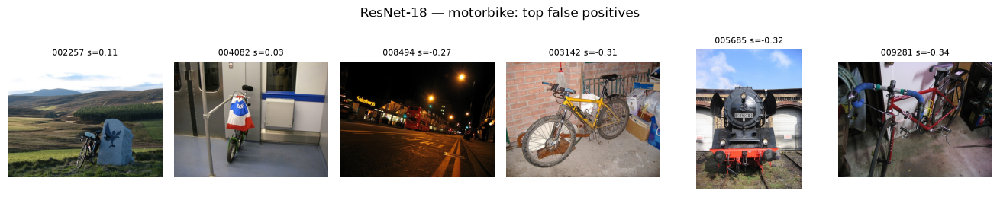

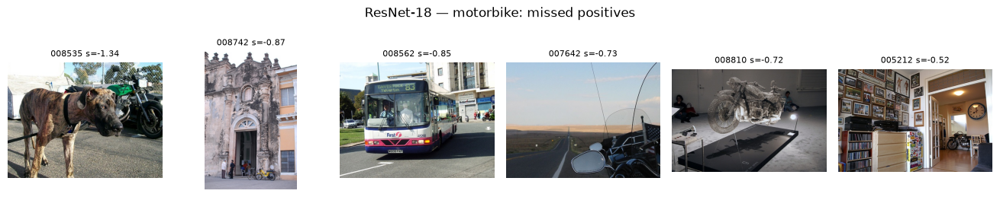

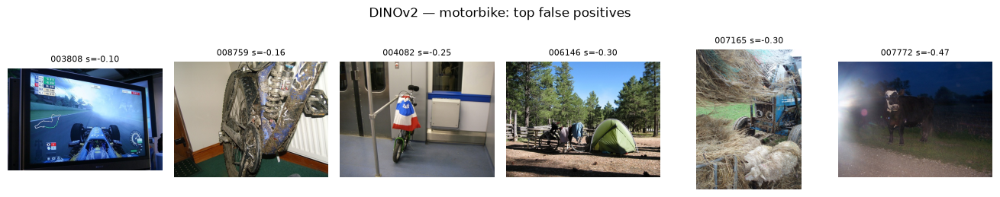

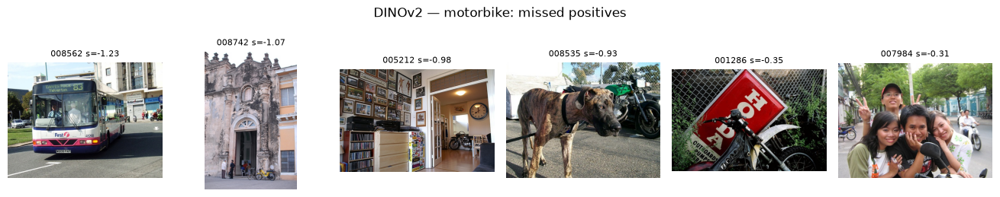

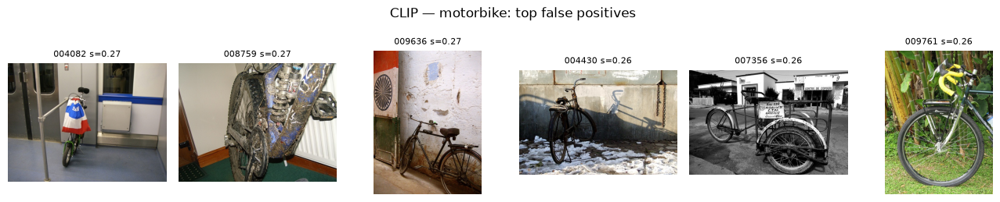

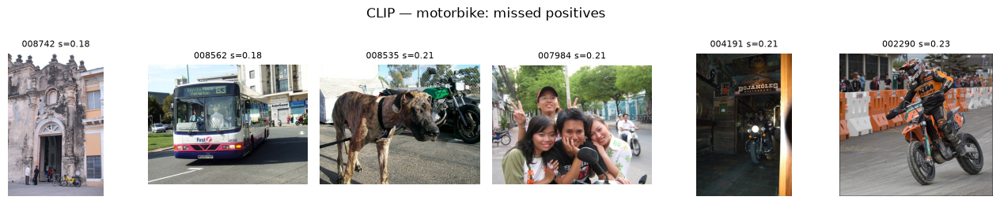

In [29]:
CLS = "motorbike"
c = CLASSES.index(CLS)
methods = {"ResNet-18": results["resnet18_layer4"]["scores"],
           "DINOv2": results["dinov2_vits14"]["scores"],
           "CLIP": S_test}
test = results["dinov2_vits14"]["test"]      # same test images for every feature

cases = {}
for method, scores in methods.items():
    cases[method] = ev.ranking_cases(scores, test, c)
    for kind in ["top false positives", "missed positives"]:
        names, s = cases[method][kind]
        fig = ev.show_grid(names, [f"{n} s={v:.2f}" for n, v in zip(names, s)],
                           title=f"{method} — {CLS}: {kind}")
        savefig(fig, f"stageF_{CLS}_{method}_{kind.replace(' ', '_')}")

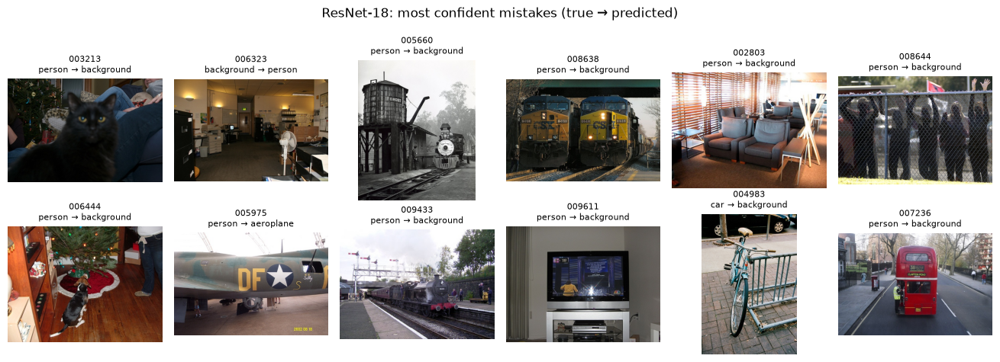

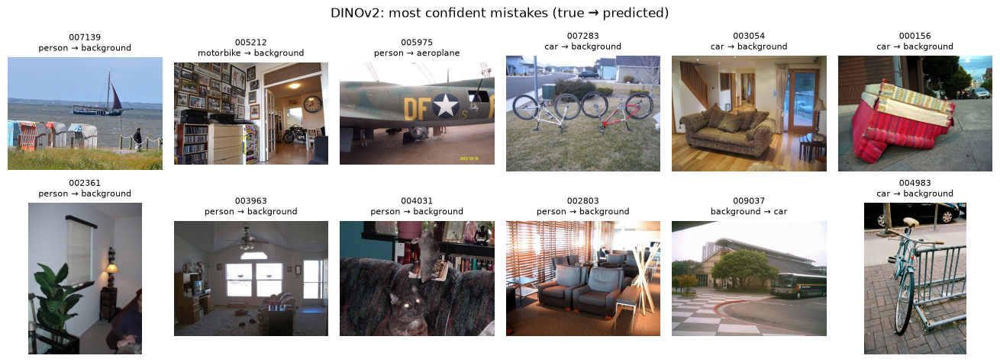

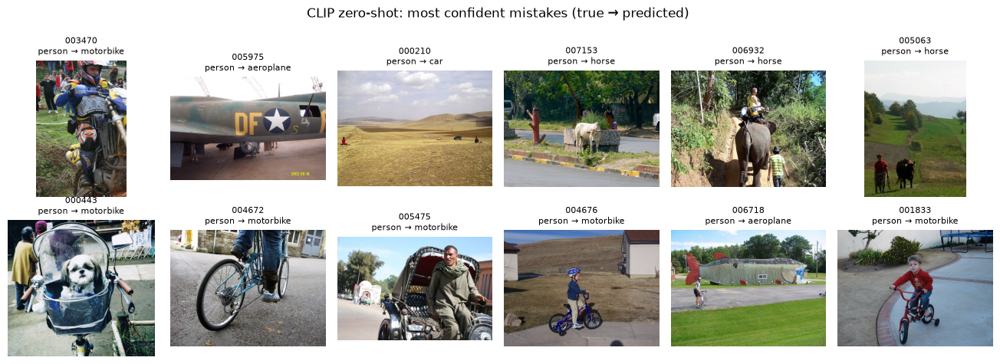

In [30]:
mistakes = {"ResNet-18": multi["resnet18_layer4"]["scores"],
            "DINOv2": multi["dinov2_vits14"]["scores"],
            "CLIP zero-shot": S_test}
for method, scores in mistakes.items():
    wrong = ev.misclassified(scores, test)
    fig = ev.show_grid([w[0] for w in wrong], [f"{n}\n{t} → {p}" for n, t, p in wrong],
                       title=f"{method}: most confident mistakes (true → predicted)")
    savefig(fig, f"stageF_mistakes_{method.split()[0]}")

Using cache found in C:\Users\Utilizador/.cache\torch\hub\facebookresearch_dinov2_main


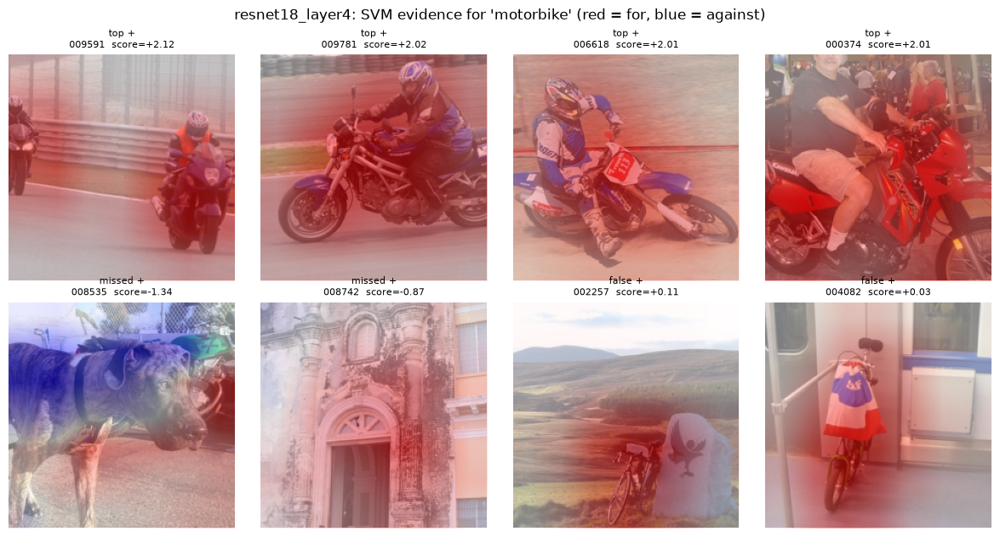

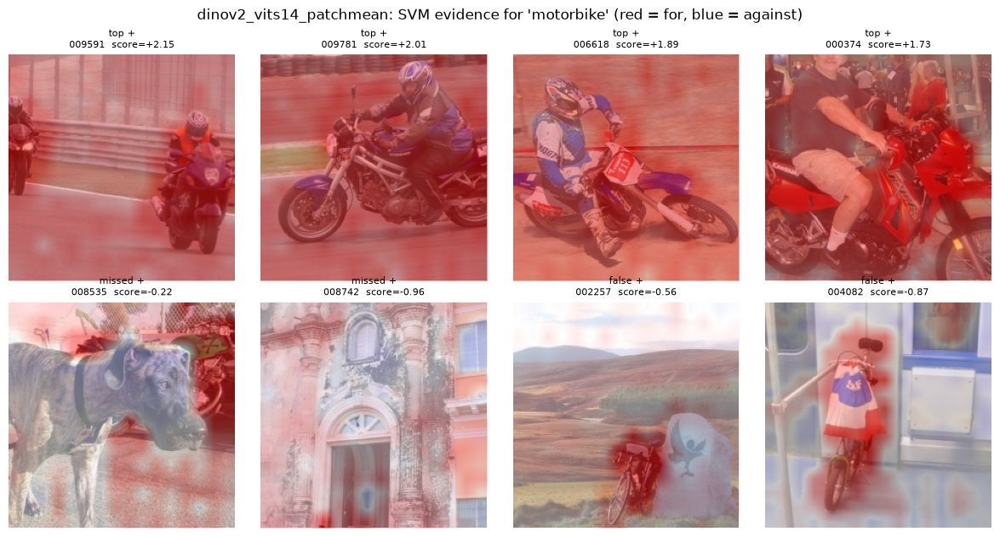

In [31]:
r = cases["ResNet-18"]
sel = list(r["top positives"][0][:4]) + list(r["missed positives"][0][:2]) \
    + list(r["top false positives"][0][:2])
tags = ["top +"] * 4 + ["missed +"] * 2 + ["false +"] * 2
for kind in ["resnet18_layer4", "dinov2_vits14_patchmean"]:
    fig = ev.show_evidence(kind, sel, results[kind]["W"][c], results[kind]["b"][c],
                           CLS, tags, device)
    savefig(fig, f"stageF_evidence_{kind}_{CLS}")

Using cache found in C:\Users\Utilizador/.cache\torch\hub\facebookresearch_dinov2_main
Using cache found in C:\Users\Utilizador/.cache\torch\hub\facebookresearch_dinov2_main


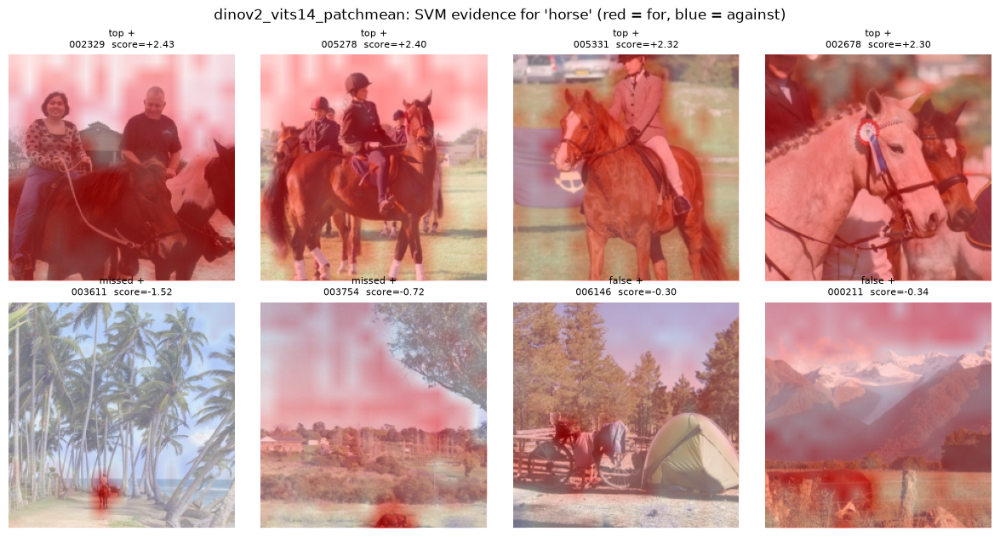

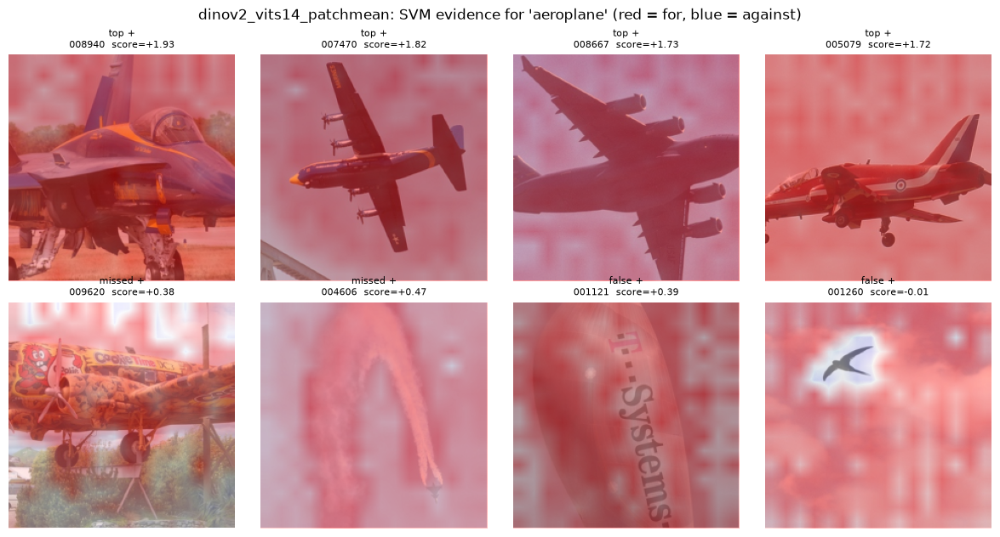

In [32]:
kind = "dinov2_vits14_patchmean"
for cls in ["horse", "aeroplane"]:
    ci = CLASSES.index(cls)
    r = ev.ranking_cases(results[kind]["scores"], test, ci, n=4)
    sel = list(r["top positives"][0][:4]) + list(r["missed positives"][0][:2]) \
        + list(r["top false positives"][0][:2])
    fig = ev.show_evidence(kind, sel, results[kind]["W"][ci], results[kind]["b"][ci],
                           cls, tags, device)
    savefig(fig, f"stageF_evidence_{kind}_{cls}")

In [33]:
val_map = {f: results[f]["per_class"].val_ap.mean()
           for f in ["resnet18_layer2", "resnet18_layer3", "resnet18_layer4"]}
best_resnet = max(val_map, key=val_map.get)
print("ResNet-18 layer chosen on val:", best_resnet)

rows = []

# pretrained features + SVM
for method, supervision, f in [
        (f"CNN ({best_resnet}) + SVM", "ImageNet-supervised + task labels", best_resnet),
        ("ViT-B/32 + SVM", "ImageNet-supervised + task labels", "vit_b_32"),
        ("DINOv2 ViT-S/14 + SVM", "self-supervised + task labels", "dinov2_vits14"),
        ("CLIP ViT-B/32 + SVM", "image-text pretraining + task labels", "clip_vit_b_32")]:
    rows.append({"method": method, "supervision": supervision,
                 "mAP vs bg": results[f]["per_class"].test_ap.mean(),
                 "mAP vs all": ap_all.loc[f, "mAP"], "dim": results[f]["dim"],
                 "extract ms/img": costs.loc[f, "ms_per_img_total"],
                 "infer µs/img": results[f]["infer_us"]})

# CLIP zero-shot: AP vs all = rank every test image by its prompt similarity
t0 = time.perf_counter()
S = clip_test.X @ text_emb.T
infer_us = 1e6 * (time.perf_counter() - t0) / len(S)
rows.append({"method": "CLIP zero-shot", "supervision": "image-text pretraining; no task labels",
             "mAP vs bg": np.mean(list(zs_ap.values())),
             "mAP vs all": np.mean([ev.ap(clip_test.Y[:, i], S[:, i]) for i in range(len(CLASSES))]),
             "dim": text_emb.shape[1],
             "extract ms/img": costs.loc["clip_vit_b_32", "ms_per_img_total"],
             "infer µs/img": infer_us})

summary = pd.DataFrame(rows).set_index("method")
summary["storage B/img"] = summary["dim"] * 4          # float32
summary.to_csv(OUT / "comparison_table.csv")
(OUT / "comparison_table.md").write_text(summary.to_markdown(floatfmt=".3f"), encoding="utf-8")
summary

ResNet-18 layer chosen on val: resnet18_layer4


,supervision,mAP vs bg,mAP vs all,dim,extract ms/img,infer µs/img,storage B/img
method,,,,,,,
CNN (resnet18_layer4) + SVM,ImageNet-supervised + task labels,0.971,0.872,512,3.923,0.828,2048
ViT-B/32 + SVM,ImageNet-supervised + task labels,0.974,0.918,768,4.108,1.207,3072
DINOv2 ViT-S/14 + SVM,self-supervised + task labels,0.988,0.949,384,4.538,0.635,1536
CLIP ViT-B/32 + SVM,image-text pretraining + task labels,0.992,0.952,512,3.826,0.822,2048
CLIP zero-shot,image-text pretraining; no task labels,0.840,0.799,512,3.826,0.180,2048
